# Assignment 4: Congressional Bill Actions

## Summary of Findings

This analysis examines congressional bill actions from the 116th U.S. Congress, focusing on the distribution of legislative actions and the individuals mentioned in House floor and Senate amendment records. The dataset contains 3,303 actions associated with 1,494 distinct bills.

Among the 116 House floor actions associated with Senate bills, 69.0% involved suspending the rules, and 15.5% involved suspending the rules and passing a bill as amended. These actions mentioned 53 unique individuals, most of whom appeared in only one or two bills.

The analysis also identified 286 Senate amendment actions associated with 131 distinct bills. Most of these bills mentioned two distinct senators. An additional analysis of party affiliations found that 69.4% of amendment actions mentioning two senators involved senators from the same party, with Republican–Republican pairings accounting for the largest share.

## 1. Data and Descriptive Statistics

I first examine the structure of the dataset and conduct basic quality checks before describing the distribution of bill categories and actions.

In [107]:
# packages
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# data
bills_actions = pd.read_csv("/Users/ladintoplu/Documents/GitHub/datasci530fall2026/Lecture 09/data_raw/bills_actions.csv")

In [108]:
# check the dimensions of the dataset
print("Number of rows:", bills_actions.shape[0])
print("Number of columns:", bills_actions.shape[1])

# check variables
print("\nVariables:")
print(bills_actions.columns.tolist())

# check missing values
print("\nMissing values:")
print(bills_actions.isna().sum())

Number of rows: 3303
Number of columns: 7

Variables:
['Congress', 'bill_number', 'bill_type', 'action', 'main_action', 'category', 'member_id']

Missing values:
Congress       0
bill_number    0
bill_type      0
action         0
main_action    0
category       0
member_id      0
dtype: int64


The dataset contains 3,303 observations and 7 variables. There are no missing values in any of the variables used in the analysis. Each row represents a bill action rather than necessarily representing a unique bill, meaning that the same bill can appear in multiple rows.

In [109]:
# different bill types
# display(bills_actions["bill_type"].value_counts())

# distinct combinations of bill type and bill number
distinct_bills = bills_actions[
    ["bill_type", "bill_number"]
].drop_duplicates()

print("Number of distinct bills:", len(distinct_bills))

# proportion of rows in each category
category_prop = (
    bills_actions["category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# proportion of rows in each main action
main_action_prop = (
    bills_actions["main_action"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# display two separate tables side by side
table1 = category_prop.rename_axis("Category").to_frame("Percent (%)")
table2 = main_action_prop.rename_axis("Main Action").to_frame("Percent (%)")

html = (
    '<div style="display:flex; gap:30px; align-items:flex-start;">'
    '<div><h4>Action Categories</h4>' + table1.to_html() + '</div>'
    '<div><h4>Main Actions</h4>' + table2.to_html() + '</div>'
    '</div>'
)

display(HTML(html))

Number of distinct bills: 1494


,Percent (%)
Category,
amendment,46.29
house bill,27.31
senate bill,15.56
house resolution,7.08
senate resolution,1.82
house joint resolution,0.67
house concurrent resolution,0.61
senate concurrent resolution,0.42
senate joint resolution,0.24


The dataset contains 1,494 distinct bills, identified by unique combinations of bill type and bill number. Amendments make up the largest share of observations (46.29%), followed by House bills (27.31%) and Senate bills (15.56%). The remaining categories each account for less than 10% of observations.

House floor actions are the most common main action in the dataset (30.88%), followed by House amendments offered (25.07%). Senate committee/subcommittee actions account for 13.14% of observations, other House amendment actions account for 12.02%, and Senate amendments proposed on the floor account for 8.66%.

## 2. House Floor Actions for Senate Bills

Next, I focus on House floor actions associated with Senate bills. I examine how often these actions involve suspending the rules and use regular expressions to identify the individuals mentioned in the action descriptions.

In [110]:
# subset House floor actions associated with Senate bills
senate_house_floor = bills_actions.query(
    "category == 'senate bill' and main_action == 'house floor actions'"
)

# number of House floor actions associated with Senate bills
print("Number of House floor actions associated with Senate bills:",
      len(senate_house_floor))

# identify actions that mention "suspend"
senate_house_floor["suspended"] = (
    senate_house_floor["action"]
    .str.contains("suspend", case=False, regex=True)
)

# proportion of actions that were suspended
suspended_prop = senate_house_floor["suspended"].mean() * 100

print("Proportion suspended:", round(suspended_prop, 2), "%")
# identify actions that were suspended as amended
senate_house_floor["suspended_amended"] = (
    senate_house_floor["action"]
    .str.contains("suspend.*as amended", case=False, regex=True)
)

# proportion of actions that were suspended as amended
suspended_amended_prop = (
    senate_house_floor["suspended_amended"].mean() * 100
)

print(
    "Proportion suspended as amended:",
    round(suspended_amended_prop, 2),
    "%"
)

#senate_house_floor.loc[
#    senate_house_floor["suspended_amended"],
#    "action"
# ].tolist()

senate_house_floor["suspended_amended"].sum()

Number of House floor actions associated with Senate bills: 116
Proportion suspended: 68.97 %
Proportion suspended as amended: 15.52 %


np.int64(18)

There are 116 House floor actions associated with Senate bills. Of these actions, 68.97% were suspended, while 15.52% were suspended as amended.

To identify suspended actions, I searched the action text for the term "suspend." To identify actions that were suspended as amended, I used the regular expression `suspend.*as amended`, which allows any text to occur between "suspend" and "as amended." As a quality check, I inspected the actions identified by this pattern and confirmed that the matched observations referred to suspending the rules and passing the bill as amended.

,name,number_of_bills
30,Mr. Takano,9
41,Ms. Haaland,6
32,Mrs. Dingell,6
1,Mr. Case,5
44,Ms. Kelly,5
23,Mr. Pallone,5
37,Ms. Bass,5
10,Mr. DeFazio,4
2,Mr. Cicilline,4
47,Ms. Norton,4



Number of unique names: 53


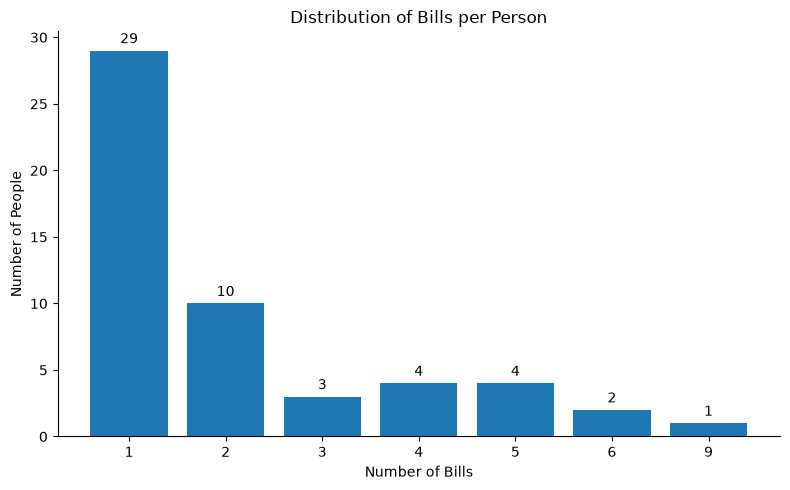

In [114]:

# extract names from House floor actions
senate_house_floor["name"] = senate_house_floor["action"].str.extract(
    r"((?:Mr|Ms|Mrs)\.\s+[A-Za-z]+)"
)

# quality check
# print("Missing names:", senate_house_floor["name"].isna().sum())

# count unique bills mentioning each person
person_bills = (
    senate_house_floor[
        ["name", "bill_type", "bill_number"]
    ]
    .drop_duplicates()
    .groupby("name")
    .size()
    .reset_index(name="number_of_bills")
    .sort_values("number_of_bills", ascending=False)
)

# display person-level dataset
display(person_bills.head(10))

# extract unique names
# unique_names = sorted(person_bills["name"].tolist())

print("\nNumber of unique names:", len(unique_names))
# print("Unique names:", unique_names)

# distribution of bills per person
bill_distribution = (
    person_bills["number_of_bills"]
    .value_counts()
    .sort_index()
)

# plot distribution
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    bill_distribution.index.astype(str),
    bill_distribution.values
)

# add value labels above bars
ax.bar_label(bars, padding=3)

ax.set_xlabel("Number of Bills")
ax.set_ylabel("Number of People")
ax.set_title("Distribution of Bills per Person")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

There are 53 unique people mentioned in the House floor actions associated with Senate bills. Most people are associated with relatively few bills: 29 of the 53 people are mentioned in only one bill, while 10 are mentioned in two bills. The number of bills per person ranges from 1 to 9, with Mr. Takano appearing in the largest number of bills (9).

Names were extracted from the action text using a regular expression that identifies the titles "Mr.", "Ms.", or "Mrs." followed by a surname. As a quality check, I confirmed that exactly one name was extracted from each of the 116 House floor actions. I also checked for repeated person-bill combinations and found one duplicate. I therefore removed duplicate person-bill combinations before calculating the number of bills associated with each person.

## 3. Senate Amendments

I then turn to Senate amendment actions, using regular expressions to extract amendment numbers and senator names. I examine how many distinct senators are mentioned across amendments associated with each bill and how frequently different senators appear together.

Number of Senate amendment actions: 286


,bill_type,bill_number,amendment_number,senator1,senator2,number_of_senators
0,s,1029,1274,McConnell,Cornyn,2
1,s,1031,2698,Hawley,NaN,1
2,s,1160,2659,McConnell,Smith,2
8,s,1253,2424,Feinstein,Cornyn,2
11,s,1309,1275,McConnell,Cardin,2
14,s,1340,940,Rubio,Menendez,2
17,s,1387,2710,Moran,Braun,2
18,s,1434,1269,McConnell,Portman,2
20,s,1430,1251,Fischer,Lankford,2
26,s,1636,2707,McConnell,Alexander,2


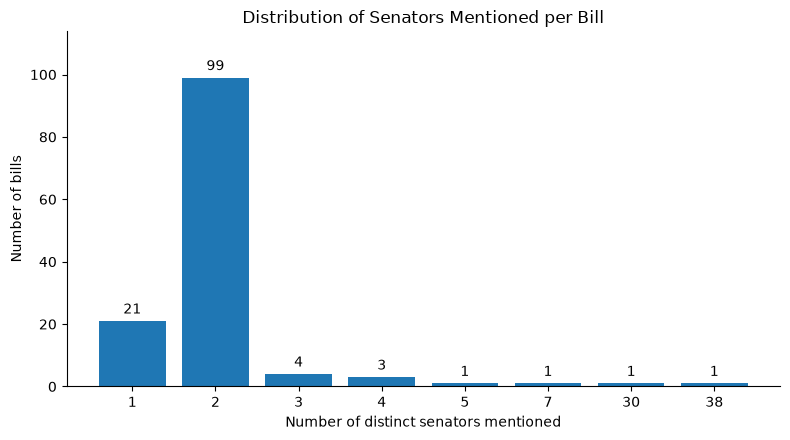

In [115]:
# subset Senate amendment actions
senate_amendments = bills_actions.query(
    "main_action == 'senate amendment proposed (on the floor)'"
).copy()

print("Number of Senate amendment actions:", len(senate_amendments))

# extract amendment numbers and senator names
senate_amendments["amendment_number"] = (
    senate_amendments["action"].str.extract(r"Amendment SA (\d+)")
)

senate_amendments["senator1"] = (
    senate_amendments["action"].str.extract(
        r"proposed by Senator ([A-Za-z]+)"
    )
)

senate_amendments["senator2"] = (
    senate_amendments["action"].str.extract(
        r"for Senator ([A-Za-z]+)"
    )
)

# count senators mentioned per amendment action
senate_amendments["number_of_senators"] = (
    1 + senate_amendments["senator2"].notna().astype(int)
)

# quality checks
# print("Missing amendment numbers:",
#      senate_amendments["amendment_number"].isna().sum())

# print("Missing Senator 1:",
#      senate_amendments["senator1"].isna().sum())

# preview the amendment-level dataset
display(
    senate_amendments[
        ["bill_type", "bill_number", "amendment_number",
         "senator1", "senator2", "number_of_senators"]
    ].head(10)
)

# combine Senator 1 and Senator 2 into one column
bill_senators = pd.concat([
    senate_amendments[
        ["bill_type", "bill_number", "senator1"]
    ].rename(columns={"senator1": "senator"}),

    senate_amendments[
        ["bill_type", "bill_number", "senator2"]
    ].rename(columns={"senator2": "senator"})
])

# count unique senators mentioned per bill
senators_per_bill = (
    bill_senators
    .dropna(subset=["senator"])
    .groupby(["bill_type", "bill_number"])["senator"]
    .nunique()
    .reset_index(name="number_of_senators")
)

# distribution of senators per bill
senator_distribution = (
    senators_per_bill["number_of_senators"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of senators")
    .reset_index(name="Number of bills")
)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    senator_distribution["Number of senators"].astype(str),
    senator_distribution["Number of bills"]
)

# Add value labels above each bar
ax.bar_label(bars, padding=3, fontsize=10)

ax.set_xlabel("Number of distinct senators mentioned")
ax.set_ylabel("Number of bills")
ax.set_title("Distribution of Senators Mentioned per Bill")

# Add space above the bars for labels
ax.set_ylim(0, senator_distribution["Number of bills"].max() * 1.15)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

There are 286 Senate amendment actions in the dataset, associated with 131 distinct bills. I used regular expressions to extract the amendment number, the first senator named in each action, and a second senator when one was present. As a quality check, I confirmed that all 286 actions produced both an amendment number and a first senator.

I then counted the number of unique senators mentioned across all amendment actions associated with each bill. Most bills (99 out of 131, or 75.6%) mention two distinct senators, while 21 bills (16.0%) mention only one. The remaining 11 bills (8.4%) mention three or more senators. Two bills stand out, with 30 and 38 distinct senators mentioned, respectively.

In [116]:
# count distinct Senator 2s mentioned for each Senator 1
senator_partners = (
    senate_amendments
    .dropna(subset=["senator2"])
    .groupby("senator1")["senator2"]
    .nunique()
    .reset_index(name="number_of_distinct_senators")
    .sort_values("number_of_distinct_senators", ascending=False)
)

display(senator_partners.head(10))

,senator1,number_of_distinct_senators
9,McConnell,57
14,Reed,25
1,Cornyn,9
2,Cramer,7
12,Murkowski,6
0,Braun,5
11,Moran,4
8,Lee,3
19,Thune,3
4,Fischer,2


McConnell has the largest number of different coauthors (57), followed by Reed (25). All other senators have 9 or fewer different coauthors.

### Additional Analysis: Party Patterns in Senate Amendment Actions

**Do Senate amendment actions involving two senators tend to involve senators from the same political party or from different political parties?**

To explore this question, I focus on Senate amendment actions that mention two senators and compare the party affiliations of the two senators named in each action.

In [118]:
us_congress_members = pd.read_csv("/Users/ladintoplu/Documents/GitHub/datasci530fall2026/Lecture 09/data_raw/us_congress_members.csv")

# inspect congressional member data
# us_congress_members.head()

In [119]:
# keep Senate members only
senators = us_congress_members[
    us_congress_members["chamber"] == "Senate"
].copy()

# check whether the same last name appears more than once
# senators[
#    senators["last_name"].duplicated(keep=False)
# ][["full_name", "last_name", "party_name"]].sort_values("last_name")

# keep amendment actions mentioning two senators
two_senator_actions = senate_amendments[
    senate_amendments["senator2"].notna()
].copy()

# identify senators mentioned in these actions
names_in_actions = set(
    two_senator_actions["senator1"]
).union(two_senator_actions["senator2"])

# create party lookup
party_lookup = (
    senators[
        senators["last_name"].isin(names_in_actions)
    ][["last_name", "party_name"]]
    .drop_duplicates()
)

# keep surnames associated with only one party
clean_party_lookup = (
    party_lookup
    .groupby("last_name")
    .filter(lambda x: x["party_name"].nunique() == 1)
    .drop_duplicates("last_name")
    .set_index("last_name")["party_name"]
    .to_dict()
)

# correct ambiguous and compound surnames for the 116th Congress
party_corrections = {
    "Warner": "Democratic",
    "Kennedy": "Republican",
    "Graham": "Republican",
    "Brown": "Democratic",
    "Johnson": "Republican",
    "Smith": "Democratic",
    "Cortez": "Democratic",
    "Van": "Democratic"
}

clean_party_lookup.update(party_corrections)

# assign party affiliations
two_senator_actions["party1"] = (
    two_senator_actions["senator1"].map(clean_party_lookup)
)

two_senator_actions["party2"] = (
    two_senator_actions["senator2"].map(clean_party_lookup)
)

# quality check
# print(
#    "Actions with missing party information:",
#    two_senator_actions[["party1", "party2"]].isna().any(axis=1).sum()
#)

# classify party pairings
two_senator_actions["party_pair"] = two_senator_actions.apply(
    lambda row: "Cross-party"
    if row["party1"] != row["party2"]
    else f"{row['party1']}–{row['party2']}",
    axis=1
)

# calculate counts and percentages
party_pairs = (
    two_senator_actions["party_pair"]
    .value_counts()
    .rename_axis("Party pairing")
    .reset_index(name="Count")
)

party_pairs["Percent (%)"] = (
    party_pairs["Count"] / len(two_senator_actions) * 100
).round(1)

display(
    party_pairs.style
    .format({"Percent (%)": "{:.1f}%"})
    .hide(axis="index")
    .set_caption("Party Pairings in Senate Amendment Actions")
)

Party pairing,Count,Percent (%)
Republican–Republican,108,55.1%
Cross-party,60,30.6%
Democratic–Democratic,28,14.3%


Among the 196 Senate amendment actions involving two senators, 69.4% involved senators from the same party, while 30.6% involved senators from different parties. Looking more closely at the specific party pairings, 55.1% were Republican–Republican, 30.6% were cross-party, and 14.3% were Democratic–Democratic. Thus, two-senator amendment actions were more often same-party than cross-party, with Republican–Republican pairings accounting for the majority of all two-senator actions.